In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

--- Dataset Summary ---
Total rows: 17379
Duplicate rows: 0
Missing values: 0
Unique timestamps: 17379

--- Numerical Feature Summary ---
                cnt          temp         atemp           hum     windspeed
count  17379.000000  17379.000000  17379.000000  17379.000000  17379.000000
mean     189.463088      0.496987      0.475775      0.627229      0.190098
std      181.387599      0.192556      0.171850      0.192930      0.122340
min        1.000000      0.020000      0.000000      0.000000      0.000000
25%       40.000000      0.340000      0.333300      0.480000      0.104500
50%      142.000000      0.500000      0.484800      0.630000      0.194000
75%      281.000000      0.660000      0.621200      0.780000      0.253700
max      977.000000      1.000000      1.000000      1.000000      0.850700


c:\Users\MaxG\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\MaxG\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\MaxG\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
c:\Users\MaxG\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 t

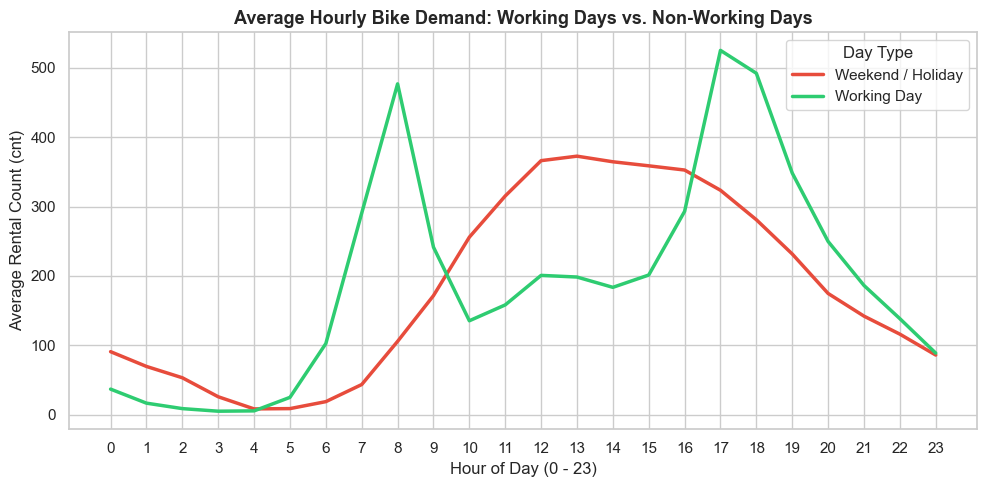


--- Rental Count Statistics Used in Weather Box Plot ---
                    count    mean     std   min   25%    50%    75%    max
weathersit                                                                
Clear/Few Clouds  11413.0  204.87  189.49   1.0  46.0  159.0  304.0  977.0
Mist/Cloudy        4544.0  175.17  165.43   1.0  40.0  133.0  257.0  957.0
Light Rain/Snow    1419.0  111.58  133.78   1.0  21.0   63.0  152.5  891.0
Heavy Rain            3.0   74.33   77.93  23.0  29.5   36.0  100.0  164.0


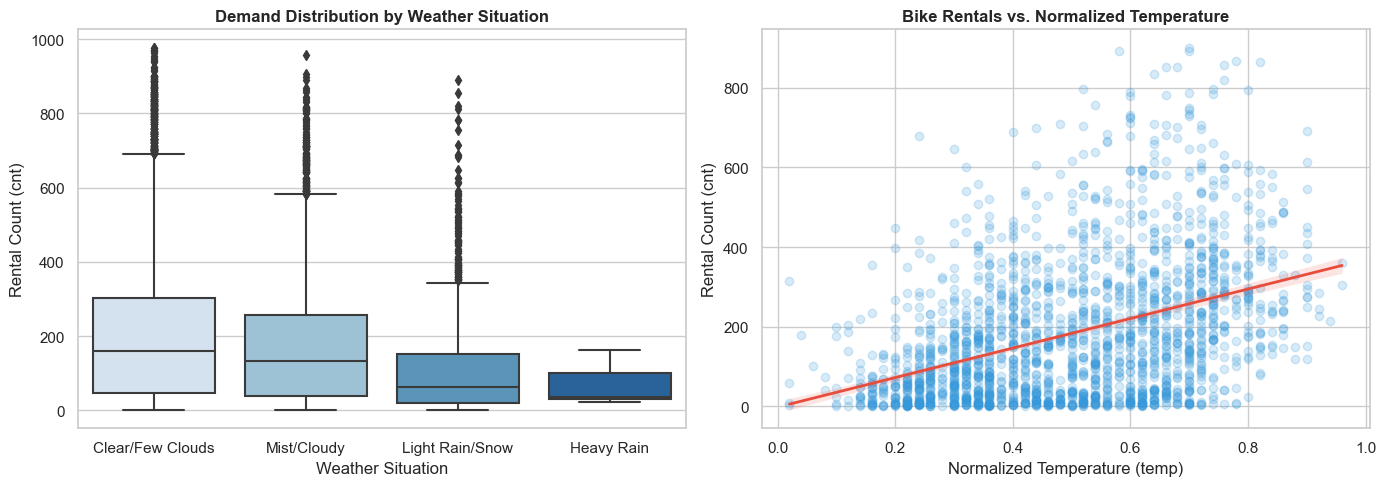

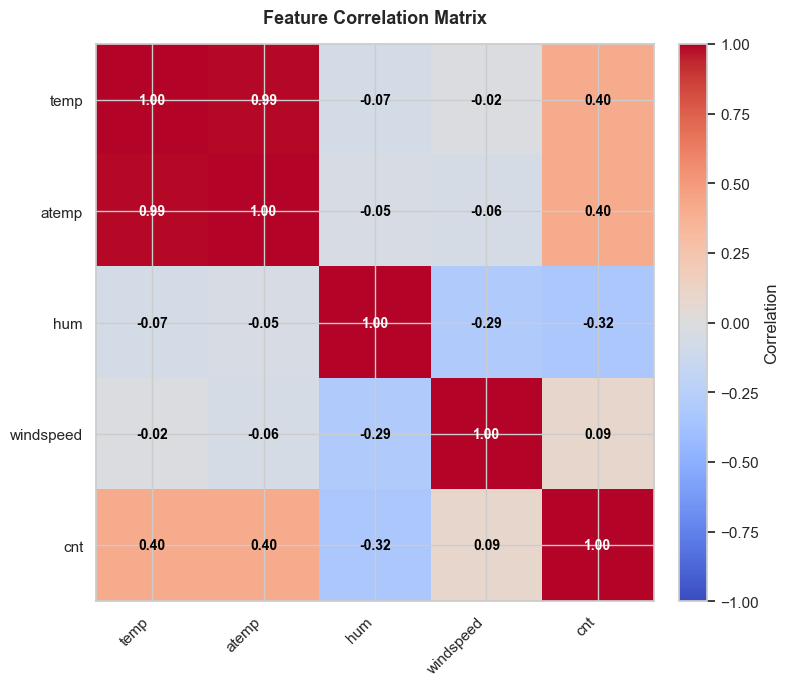

In [6]:
# Configure plotting style and load the hourly dataset
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11})

hour_df = pd.read_csv('data/hour.csv')
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])
hour_df = hour_df.sort_values(['dteday', 'hr']).reset_index(drop=True)

# Basic data integrity checks
print('--- Dataset Summary ---')
print(f'Total rows: {len(hour_df)}')
print(f'Duplicate rows: {hour_df.duplicated().sum()}')
print(f'Missing values: {hour_df.isna().sum().sum()}')
print(f'Unique timestamps: {hour_df[["dteday", "hr"]].drop_duplicates().shape[0]}')

# Summary statistics
summary_cols = ['cnt', 'temp', 'atemp', 'hum', 'windspeed']
print('\n--- Numerical Feature Summary ---')
print(hour_df[summary_cols].describe())

# Plot 1: Commute patterns by working-day status
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hour_df,
    x='hr',
    y='cnt',
    hue='workingday',
    palette={0: '#e74c3c', 1: '#2ecc71'},
    errorbar=None,
    linewidth=2.5
)
plt.title('Average Hourly Bike Demand: Working Days vs. Non-Working Days', fontsize=13, fontweight='bold')
plt.xlabel('Hour of Day (0 - 23)')
plt.ylabel('Average Rental Count (cnt)')
plt.legend(['Weekend / Holiday', 'Working Day'], title='Day Type')
plt.xticks(range(24))
plt.tight_layout()
plt.savefig('hourly_commute_pattern.png', dpi=300)
plt.show()

# Plot 2: Weather and temperature effects
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
weather_labels = {
    1: 'Clear/Few Clouds',
    2: 'Mist/Cloudy',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain'
}

weather_stats = (
    hour_df.groupby('weathersit')['cnt']
    .describe()
    .rename(index=weather_labels)
)
print('\n--- Rental Count Statistics Used in Weather Box Plot ---')
print(weather_stats.round(2))

sns.boxplot(data=hour_df, x='weathersit', y='cnt', ax=axes[0], palette='Blues')
axes[0].set_title('Demand Distribution by Weather Situation', fontweight='bold')
axes[0].set_xlabel('Weather Situation')
axes[0].set_ylabel('Rental Count (cnt)')
axes[0].set_xticks(range(4))
axes[0].set_xticklabels([weather_labels.get(code, str(code)) for code in range(1, 5)])

sns.regplot(
    data=hour_df.sample(2000, random_state=42),
    x='temp',
    y='cnt',
    ax=axes[1],
    scatter_kws={'alpha': 0.2, 'color': '#3498db'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)
axes[1].set_title('Bike Rentals vs. Normalized Temperature', fontweight='bold')
axes[1].set_xlabel('Normalized Temperature (temp)')
axes[1].set_ylabel('Rental Count (cnt)')

plt.tight_layout()
plt.savefig('weather_temp_impact.png', dpi=300)
plt.show()

# Plot 3: Correlation matrix
corr_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
corr = hour_df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04, label='Correlation')
ax.set_xticks(np.arange(len(corr_cols)))
ax.set_yticks(np.arange(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=11)
ax.set_yticklabels(corr_cols, fontsize=11)

for row_index in range(len(corr_cols)):
    for col_index in range(len(corr_cols)):
        value = corr.iloc[row_index, col_index]
        text_color = 'white' if abs(value) > 0.55 else 'black'
        ax.text(col_index, row_index, f'{value:.2f}', ha='center', va='center', color=text_color, fontsize=10, fontweight='bold')

ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=300)
plt.show()

In [7]:
# Check extreme outliers or macro events
highest_demand = hour_df.sort_values('cnt', ascending=False)[
    ['dteday', 'hr', 'workingday', 'weathersit', 'temp', 'cnt']
].head(10)
print('Top 10 highest-demand hours:')
print(highest_demand)

lowest_commute_demand = hour_df[
    (hour_df['workingday'] == 1) & (hour_df['hr'] == 17)
].sort_values('cnt')[
    ['dteday', 'hr', 'weathersit', 'temp', 'cnt']
].head(10)
print('\nLowest 10 demand hours during peak commute (5 PM on working days):')
print(lowest_commute_demand)

Top 10 highest-demand hours:
          dteday  hr  workingday  weathersit  temp  cnt
14773 2012-09-12  18           1           1  0.66  977
14964 2012-09-20  17           1           1  0.64  976
14748 2012-09-11  17           1           1  0.70  970
14725 2012-09-10  18           1           1  0.62  968
15084 2012-09-25  17           1           1  0.66  967
15780 2012-10-24  17           1           1  0.66  963
10622 2012-03-23  17           1           2  0.72  957
15108 2012-09-26  17           1           1  0.74  953
15444 2012-10-10  17           1           1  0.58  948
15588 2012-10-16  17           1           1  0.52  943

Lowest 10 demand hours during peak commute (5 PM on working days):
          dteday  hr  weathersit  temp  cnt
17205 2012-12-24  17           3  0.24   26
586   2011-01-26  17           3  0.20   26
8065  2011-12-07  17           3  0.40   52
17252 2012-12-26  17           3  0.26   53
2587  2011-04-22  17           3  0.32   69
1330  2011-02-28  17   

In [12]:
import hashlib
from pathlib import Path

import joblib
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

from src.evaluate import calculate_mad
from src.pipeline import build_model_pipeline

# Load the data in chronological order.
data_path = Path('data/hour.csv')
model_df = pd.read_csv(data_path).sort_values('instant').reset_index(drop=True)

# Reserve the final 15% as an unseen chronological holdout.
holdout_start = int(len(model_df) * 0.85)
train_val_df = model_df.iloc[:holdout_start].copy()
test_df = model_df.iloc[holdout_start:].copy()

# Remove identifiers, leakage columns, and the redundant temperature representation.
feature_drop_cols = ['instant', 'dteday', 'casual', 'registered', 'cnt', 'atemp']
X_train_val = train_val_df.drop(columns=feature_drop_cols)
y_train_val = train_val_df['cnt']
X_test = test_df.drop(columns=feature_drop_cols)
y_test = test_df['cnt']

model_path = Path('best_model.joblib')
dataset_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
expected_metadata = {
    'data_path': str(data_path),
    'dataset_hash': dataset_hash,
    'dataset_rows': len(model_df),
    'training_rows': len(train_val_df),
    'holdout_fraction': 0.15,
    'training_start': str(train_val_df['dteday'].min()),
    'training_end': str(train_val_df['dteday'].max()),
    'feature_drop_cols': feature_drop_cols,
}

cached_model = None
if model_path.exists():
    cached_model = joblib.load(model_path)

cache_matches = (
    cached_model is not None
    and cached_model.get('metadata') == expected_metadata
)

if cache_matches:
    best_model = cached_model['model']
    best_search_name = cached_model['best_search_name']
    best_params = cached_model['best_params']
    best_cv_score = cached_model['best_cv_score']
    print(f'Loaded saved model from {model_path}.')
    print('Grid search skipped: the saved model matches the current dataset.')
else:
    print('No matching saved model found. Running grid search.')

    # Tune both model families on the same rolling chronological validation folds.
    time_series_cv = TimeSeriesSplit(n_splits=5)
    common_model_grid = {
        'regressor__max_iter': [300],
        'regressor__max_leaf_nodes': [31, 63],
        'regressor__learning_rate': [0.03, 0.1],
        'regressor__l2_regularization': [0.0, 0.1]
    }

    # Search 1: squared-error and Poisson loss.
    param_grid = {
        **common_model_grid,
        'regressor__loss': ['squared_error', 'poisson']
    }
    grid_search = GridSearchCV(
        estimator=build_model_pipeline(),
        param_grid=param_grid,
        cv=time_series_cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1,
        refit=True
    )
    grid_search.fit(X_train_val, y_train_val)

    # Search 2: quantile loss, with quantile as an explicit hyperparameter.
    quantile_param_grid = {
        **common_model_grid,
        'regressor__loss': ['quantile'],
        'regressor__quantile': [0.5, 0.7, 0.9]
    }
    grid_search_quantile = GridSearchCV(
        estimator=build_model_pipeline(),
        param_grid=quantile_param_grid,
        cv=time_series_cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1,
        refit=True
    )
    grid_search_quantile.fit(X_train_val, y_train_val)

    # Select and persist the model with the best cross-validation score.
    search_results = {
        'squared_error_or_poisson': grid_search,
        'quantile': grid_search_quantile
    }
    best_search_name, best_search = max(
        search_results.items(),
        key=lambda item: item[1].best_score_
    )
    best_model = best_search.best_estimator_
    best_params = best_search.best_params_
    best_cv_score = best_search.best_score_

    joblib.dump(
        {
            'model': best_model,
            'metadata': expected_metadata,
            'best_search_name': best_search_name,
            'best_params': best_params,
            'best_cv_score': best_cv_score,
        },
        model_path,
    )
    print(f'Saved best model to {model_path}.')

print(f"Training data: {expected_metadata['data_path']}")
print(f"Dataset fingerprint: {expected_metadata['dataset_hash'][:12]}...")
print(
    f"Training rows: {expected_metadata['training_rows']} "
    f"({expected_metadata['training_start']} to {expected_metadata['training_end']})"
)
print('Model:', best_model.named_steps['regressor'].__class__.__name__)
print('Search:', best_search_name)
print('Parameters:', best_params)
print(f'CV MAD: {-best_cv_score:.2f}')

# Evaluate the selected model once on the unseen holdout period.
test_preds = best_model.predict(X_test)
print(f'Holdout test MAD: {calculate_mad(y_test, test_preds):.2f}')

Loaded saved model from best_model.joblib.
Grid search skipped: the saved model matches the current dataset.
Training data: data\hour.csv
Dataset fingerprint: e03de4ee4ef4...
Training rows: 14772 (2011-01-01 to 2012-09-12)
Model: HistGradientBoostingRegressor
Search: quantile
Parameters: {'regressor__l2_regularization': 0.0, 'regressor__learning_rate': 0.1, 'regressor__loss': 'quantile', 'regressor__max_iter': 300, 'regressor__max_leaf_nodes': 31, 'regressor__quantile': 0.9}
CV MAD: 48.61
Holdout test MAD: 49.76


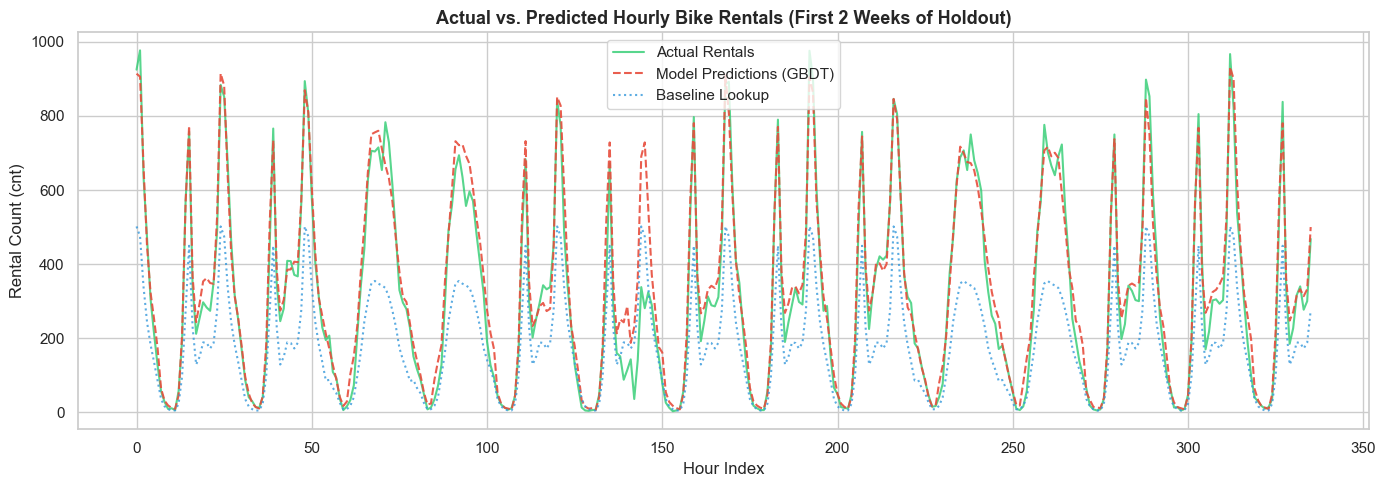

In [9]:
# Compare actual and predicted demand for the first two weeks of the holdout period
test_sample = test_df.iloc[:24 * 14].copy()
X_test_sample = test_sample.drop(columns=feature_drop_cols)
y_test_sample = test_sample['cnt']
preds_sample = best_model.predict(X_test_sample)

baseline_lookup = train_val_df.groupby(['workingday', 'hr'])['cnt'].mean().to_dict()
base_preds_sample = test_sample.apply(
    lambda row: baseline_lookup.get((row['workingday'], row['hr']), y_train_val.mean()),
    axis=1
).to_numpy()

plt.figure(figsize=(14, 5))
plt.plot(y_test_sample.to_numpy(), label='Actual Rentals', color='#2ecc71', alpha=0.8, linewidth=1.5)
plt.plot(preds_sample, label='Model Predictions (GBDT)', color='#e74c3c', linestyle='--', alpha=0.9, linewidth=1.5)
plt.plot(base_preds_sample, label='Baseline Lookup', color='#3498db', linestyle=':', alpha=0.8, linewidth=1.5)
plt.title('Actual vs. Predicted Hourly Bike Rentals (First 2 Weeks of Holdout)', fontsize=13, fontweight='bold')
plt.xlabel('Hour Index')
plt.ylabel('Rental Count (cnt)')
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('holdout_demand_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

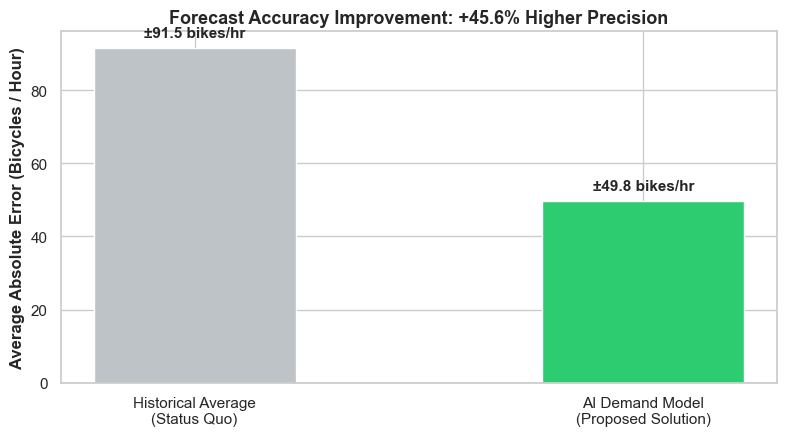


--- Prediction Error Statistics Used in Error Box Plot ---
                                       count   mean     std     min    25%  \
Model                                                                        
AI Demand Model\n(Proposed Solution)  2607.0 -25.29   72.44 -510.06 -50.98   
Historical Average\n(Status Quo)      2607.0  54.77  123.28 -475.79  -2.24   

                                        50%     75%     max  
Model                                                        
AI Demand Model\n(Proposed Solution) -14.48    3.48  349.93  
Historical Average\n(Status Quo)      29.35  107.06  502.13  


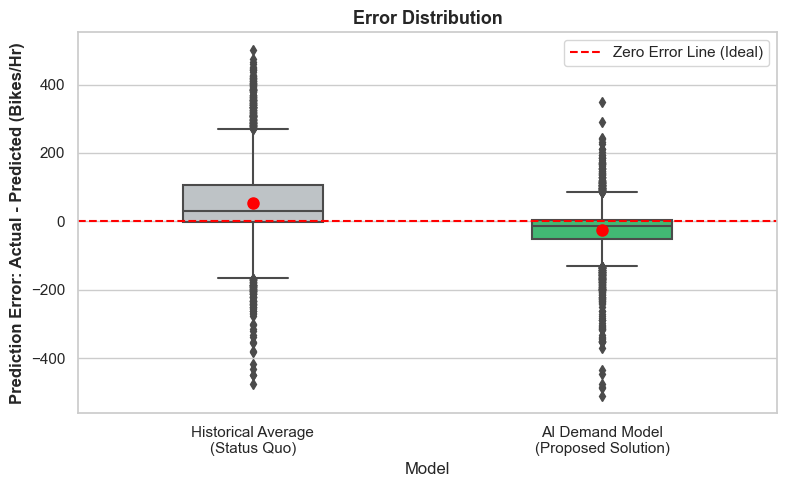

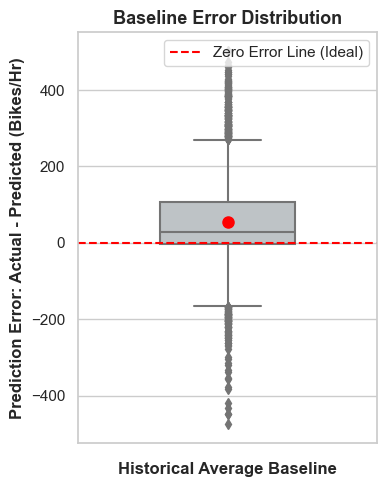

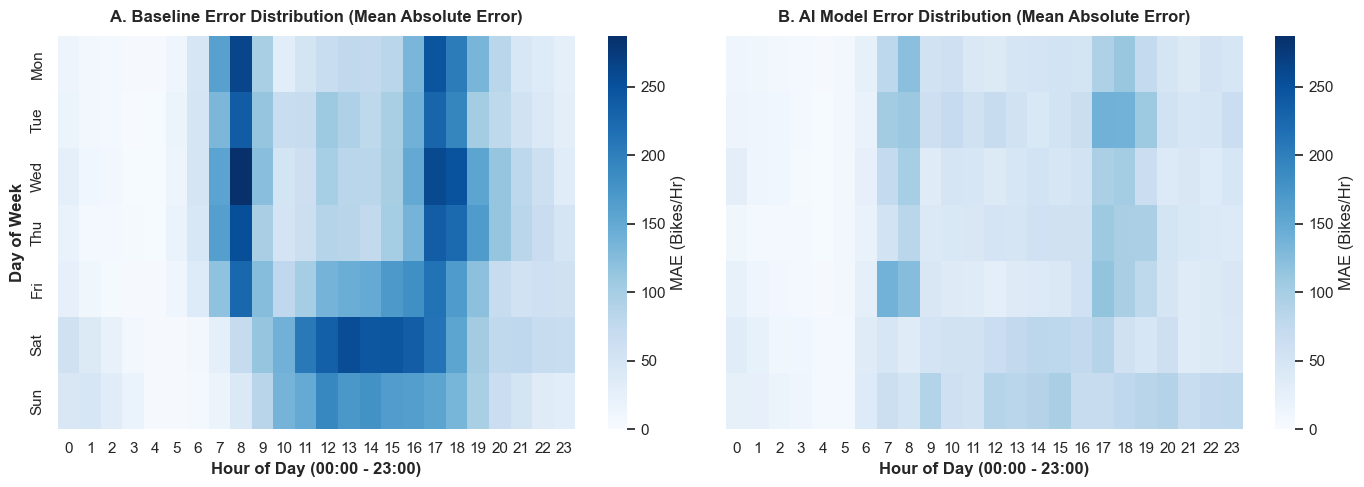

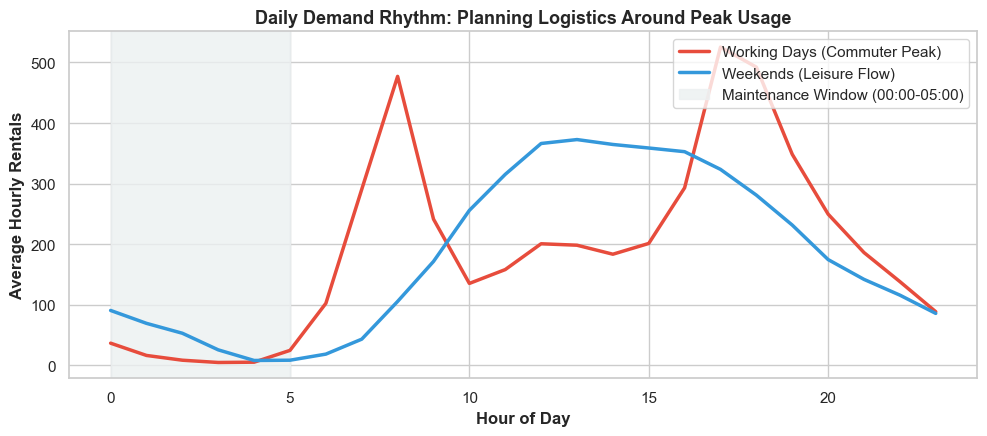

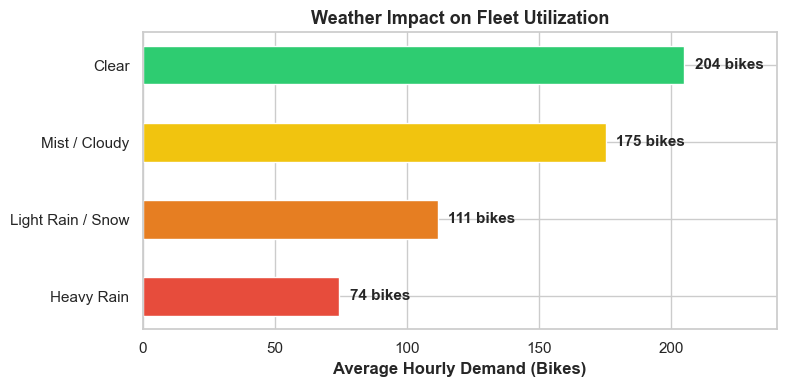

In [10]:
# Build the baseline and model error data used by the operational plots
baseline_lookup = train_val_df.groupby(['workingday', 'hr'])['cnt'].mean().to_dict()
test_df['pred_model'] = test_preds
test_df['pred_base'] = test_df.apply(
    lambda row: baseline_lookup.get((row['workingday'], row['hr']), y_train_val.mean()),
    axis=1
)
test_df['err_base'] = test_df['cnt'] - test_df['pred_base']
test_df['err_model'] = test_df['cnt'] - test_df['pred_model']

# Plot 1: Executive accuracy benchmark
mad_base = np.abs(test_df['err_base']).mean()
mad_model = np.abs(test_df['err_model']).mean()
pct_improvement = ((mad_base - mad_model) / mad_base) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
categories = ['Historical Average\n(Status Quo)', 'AI Demand Model\n(Proposed Solution)']
mad_values = [mad_base, mad_model]
bars = ax.bar(categories, mad_values, color=['#bdc3c7', '#2ecc71'], width=0.45)
ax.set_ylabel('Average Absolute Error (Bicycles / Hour)', fontweight='bold')
ax.set_title(f'Forecast Accuracy Improvement: +{pct_improvement:.1f}% Higher Precision', fontsize=13, fontweight='bold')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f'±{bar.get_height():.1f} bikes/hr', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('slide_plot_1_accuracy_benchmark.png', dpi=300)
plt.show()

# Plot 2: Prediction-error distributions
plot_df = pd.DataFrame({
    'Error': np.concatenate([test_df['err_base'], test_df['err_model']]),
    'Model': (
        ['Historical Average\n(Status Quo)'] * len(test_df)
        + ['AI Demand Model\n(Proposed Solution)'] * len(test_df)
    )
})
error_stats = plot_df.groupby('Model')['Error'].describe()
print('\n--- Prediction Error Statistics Used in Error Box Plot ---')
print(error_stats.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=plot_df,
    x='Model',
    y='Error',
    palette=['#bdc3c7', '#2ecc71'],
    width=0.4,
    ax=ax,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor': 'red', 'markersize': '8'}
)
ax.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error Line (Ideal)')
ax.set_ylabel('Prediction Error: Actual - Predicted (Bikes/Hr)', fontweight='bold')
ax.set_title('Error Distribution', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('slide_plot_1_error_boxplot.png', dpi=300)
plt.show()

# Plot 2a: Baseline-only error distribution
baseline_plot_df = plot_df[plot_df['Model'] == 'Historical Average\n(Status Quo)']
fig, ax = plt.subplots(figsize=(4, 5))
sns.boxplot(
    data=baseline_plot_df,
    y='Error',
    color='#bdc3c7',
    width=0.45,
    ax=ax,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'red', 'markeredgecolor': 'red', 'markersize': '8'}
)
ax.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error Line (Ideal)')
ax.set_xlabel('Historical Average Baseline', fontweight='bold')
ax.set_ylabel('Prediction Error: Actual - Predicted (Bikes/Hr)', fontweight='bold')
ax.set_title('Baseline Error Distribution', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('slide_plot_1_baseline_error_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 3: Baseline and model error heatmaps
day_names = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
test_df['day_name'] = test_df['weekday'].map(day_names)
test_df['abs_error_base'] = np.abs(test_df['err_base'])
test_df['abs_error_model'] = np.abs(test_df['err_model'])
weekday_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
pivot_mae_base = test_df.pivot_table(index='day_name', columns='hr', values='abs_error_base', aggfunc='mean').reindex(weekday_order)
pivot_mae_model = test_df.pivot_table(index='day_name', columns='hr', values='abs_error_model', aggfunc='mean').reindex(weekday_order)
heatmap_vmax = max(pivot_mae_base.max().max(), pivot_mae_model.max().max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.heatmap(
    pivot_mae_base,
    ax=axes[0],
    cmap='Blues',
    vmin=0,
    vmax=heatmap_vmax,
    cbar_kws={'label': 'MAE (Bikes/Hr)'}
)
axes[0].set_title('A. Baseline Error Distribution (Mean Absolute Error)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Hour of Day (00:00 - 23:00)', fontweight='bold')
axes[0].set_ylabel('Day of Week', fontweight='bold')
sns.heatmap(
    pivot_mae_model,
    ax=axes[1],
    cmap='Blues',
    vmin=0,
    vmax=heatmap_vmax,
    cbar_kws={'label': 'MAE (Bikes/Hr)'}
)
axes[1].set_title('B. AI Model Error Distribution (Mean Absolute Error)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Hour of Day (00:00 - 23:00)', fontweight='bold')
axes[1].set_ylabel('')
axes[0].tick_params(axis='x', rotation=0)
axes[1].tick_params(axis='x', rotation=0)


plt.tight_layout()
plt.savefig('slide_plot_2_dual_heatmap.png', dpi=300)
plt.show()

# Plot 4: Daily demand rhythm
commute_profile = model_df.groupby(['workingday', 'hr'])['cnt'].mean().unstack(level=0)
plt.figure(figsize=(10, 4.5))
plt.plot(commute_profile.index, commute_profile[1], label='Working Days (Commuter Peak)', color='#e74c3c', linewidth=2.5)
plt.plot(commute_profile.index, commute_profile[0], label='Weekends (Leisure Flow)', color='#3498db', linewidth=2.5)
plt.axvspan(0, 5, color='#ecf0f1', alpha=0.8, label='Maintenance Window (00:00-05:00)')
plt.title('Daily Demand Rhythm: Planning Logistics Around Peak Usage', fontsize=13, fontweight='bold')
plt.xlabel('Hour of Day', fontweight='bold')
plt.ylabel('Average Hourly Rentals', fontweight='bold')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('slide_plot_3_rebalancing_window.png', dpi=300)
plt.show()

# Plot 5: Weather impact on fleet utilization
weather_labels = {1: 'Clear', 2: 'Mist / Cloudy', 3: 'Light Rain / Snow', 4: 'Heavy Rain'}
weather_impact = (
    model_df.assign(weather_desc=model_df['weathersit'].map(weather_labels))
    .groupby('weather_desc')['cnt']
    .mean()
    .reindex(list(weather_labels.values()))
    .dropna()
)

plt.figure(figsize=(8, 4))
bars = plt.barh(weather_impact.index, weather_impact.values, color=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c'], height=0.5)
plt.xlabel('Average Hourly Demand (Bikes)', fontweight='bold')
plt.title('Weather Impact on Fleet Utilization', fontsize=13, fontweight='bold')
for bar in bars:
    plt.text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2, f'{int(bar.get_width())} bikes', va='center', fontweight='bold')
plt.xlim(0, 240)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('slide_plot_4_weather_impact.png', dpi=300)
plt.show()

In [ ]:
# Set random seed for reproducibility
np.random.seed(42)

# Generate 3 weeks of hourly dates (21 days * 24 hours = 504 records)
start_date = pd.Timestamp("2013-01-01 00:00:00")
dates = pd.date_range(start=start_date, periods=504, freq="h")

mock_df = pd.DataFrame({
    "instant": np.arange(1, 505),
    "dteday": dates.strftime("%Y-%m-%d"),
    "season": 1,  # Winter
    "yr": 2,  # 2013 (relative to 2011 index)
    "mnth": dates.month,
    "hr": dates.hour,
    "holiday": 0,
    "weekday": dates.weekday,  # 0 = Monday ... 6 = Sunday
    "workingday": [1 if w < 5 else 0 for w in dates.weekday],
    "weathersit": np.random.choice([1, 2, 3], size=504, p=[0.65, 0.25, 0.10]),
    "temp": np.round(
        np.random.normal(loc=0.28, scale=0.08, size=504).clip(0.05, 0.55), 2
    ),
    "atemp": np.round(
        (np.random.normal(loc=0.28, scale=0.08, size=504) * 1.05 + 0.02).clip(
            0.05, 0.60
        ),
        2,
    ),
    "hum": np.round(
        np.random.normal(loc=0.55, scale=0.15, size=504).clip(0.15, 0.95), 2
    ),
    "windspeed": np.round(
        np.random.normal(loc=0.19, scale=0.09, size=504).clip(0.0, 0.55), 2
    ),
})

# Save for inference testing
mock_df.to_csv("data/mock_test_data_3weeks.csv", index=False)

Predictions saved to data/mock_test_data_3weeks_predictions.csv
       dteday  hr        cnt
0  2013-01-01   0  18.848038
1  2013-01-01   1   7.759215
2  2013-01-01   2   5.157138
3  2013-01-01   3   5.090389
4  2013-01-01   4   5.573725


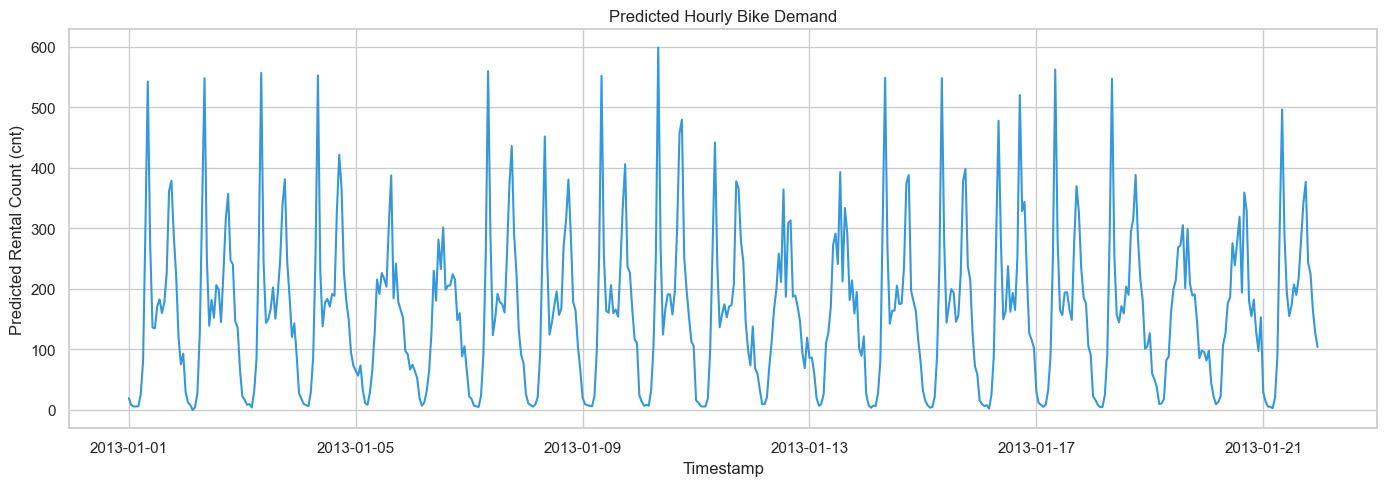

Prediction plot saved to mock_test_data_3weeks_predictions.png


In [14]:
from src.predict import predict_and_save
from src.visualization import plot_predictions

mock_input_path = 'data/mock_test_data_3weeks.csv'
prediction_output_path = 'data/mock_test_data_3weeks_predictions.csv'
plot_output_path = 'mock_test_data_3weeks_predictions.png'

mock_predictions = predict_and_save(
    dataset=pd.read_csv(mock_input_path),
    model_path='best_model.joblib',
    output_path=prediction_output_path,
)

print(f'Predictions saved to {prediction_output_path}')
print(mock_predictions[['dteday', 'hr', 'cnt']].head())

plot_predictions(
    dataset=mock_predictions,
    output_path=plot_output_path,
)
plt.show()
print(f'Prediction plot saved to {plot_output_path}')